In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 


In [2]:
rng=np.random.default_rng(seed=42)
n=200

In [3]:
bp=rng.normal(loc=120,scale=15,size=n).round(1)

In [ ]:
wait =rng.gamma(shape=2,scale=30,size=n).round(1)

In [5]:
bp[rng.choice(n, 5, replace=False)] = rng.uniform(190, 230, 5).round(1)
wait[rng.choice(n, 5, replace=False)] = rng.uniform(350, 500, 5).round(1)

In [6]:
df = pd.DataFrame({"bp": bp, "wait": wait})

In [7]:
df.to_csv("normalisation_data.csv", index=False)

In [8]:
print(df.describe().round(2))

           bp    wait
count  200.00  200.00
mean   121.72   72.46
std     18.72   74.97
min     88.00    2.80
25%    110.40   32.38
50%    119.80   54.75
75%    129.43   87.48
max    221.10  488.70


In [9]:
df.head()

,bp,wait
0,124.6,64.2
1,104.4,53.6
2,131.3,5.2
3,134.1,23.9
4,90.7,23.1


In [10]:
df=pd.read_csv('normalisation_data.csv')

In [11]:
df.shape

(200, 2)

In [12]:
df.head()


,bp,wait
0,124.6,64.2
1,104.4,53.6
2,131.3,5.2
3,134.1,23.9
4,90.7,23.1


In [13]:
df.describe()

,bp,wait
count,200.000000,200.0000
mean,121.723000,72.4645
std,18.717089,74.9703
min,88.000000,2.8000
25%,110.400000,32.3750
50%,119.800000,54.7500
75%,129.425000,87.4750
max,221.100000,488.7000


 COL              bp            wait     
 Mean            121.72       72.46   
 Median         119.80        54.75     
 Min            88.00          2.80     
 Max            221.10        488.70    
 comparison  Mean > Median Mean > Median 


A large gap between the mean and median indicates a skewed distribution caused by extreme values or outliers.

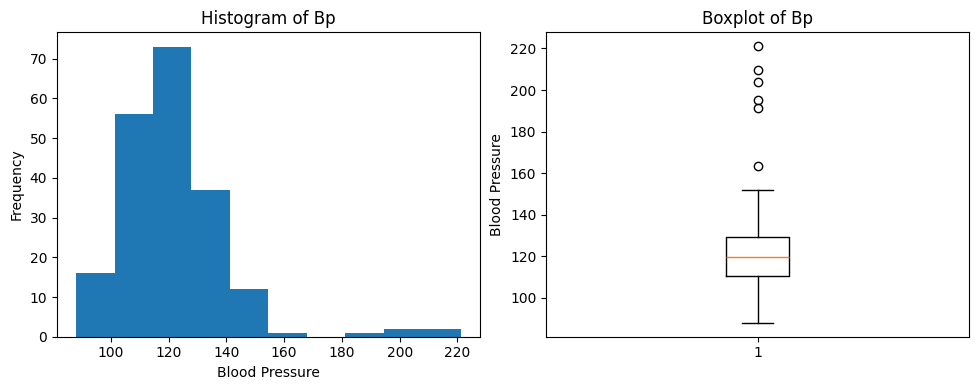

In [22]:
plt.figure(figsize=(10, 4))
plt.subplot(1,2,1)
plt.hist(df["bp"])
plt.title("Histogram of Bp")
plt.xlabel("Blood Pressure")
plt.ylabel("Frequency")


plt.subplot(1,2,2)
plt.title("Boxplot of Bp")
plt.ylabel("Blood Pressure")
plt.tight_layout()
plt.boxplot(df["bp"])
plt.show()

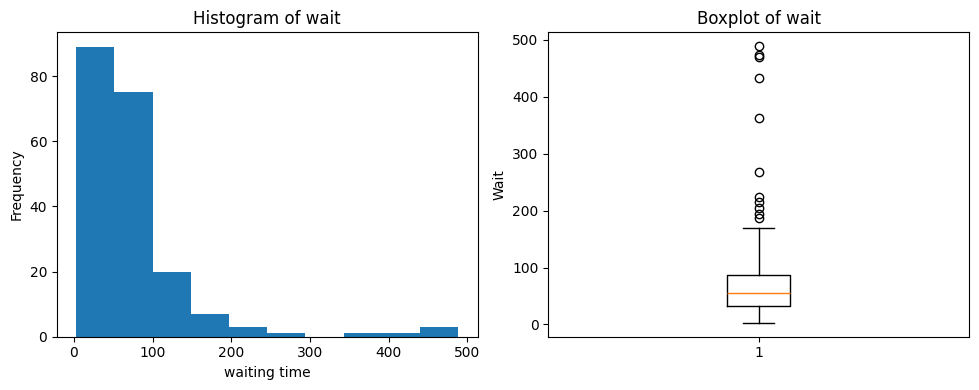

In [23]:
plt.figure(figsize=(10, 4))
plt.subplot(1,2,1)
plt.hist(df["wait"])
plt.title("Histogram of wait")
plt.xlabel("waiting time")
plt.ylabel("Frequency")


plt.subplot(1,2,2)
plt.title("Boxplot of wait")
plt.ylabel("Wait")
plt.tight_layout()
plt.boxplot(df["wait"])
plt.show()

Symmetry: bp is more symmetric, while wait is right-skewed.
Upper Tail: wait has a much longer upper tail,reaching nearly 500.
Outliers: Both have outliers. bp has a few high outliers, while wait has many extreme high outliers.

In [24]:
print("Skewness of BP:",df["bp"].skew())
print("Skewness of Wait:",df["wait"].skew())

Skewness of BP: 2.2034292021486865
Skewness of Wait: 3.4447160606920275


bp:2.2034292021486865 
wait: 3.4447160606920275
Positive skewness means the distribution has a longer tail on the right.
wait is more skewed than bp, which matches the plots.

B.2 Min Scaling ( x − min )

In [25]:
from sklearn.preprocessing import MinMaxScaler

In [26]:
scaler = MinMaxScaler()

In [27]:
df["bp_scaled"] = scaler.fit_transform(df[["bp"]])
df["wait_scaled"] = scaler.fit_transform(df[["wait"]])

In [28]:
print("BP min:", df["bp_scaled"].min())
print("BP max:", df["bp_scaled"].max())

BP min: 0.0
BP max: 1.0


In [29]:
print("Wait min:", df["wait_scaled"].min())
print("Wait max:", df["wait_scaled"].max())

Wait min: 0.0
Wait max: 1.0


Both columns now have a minimum of exactly 0 and a maximum of 1.

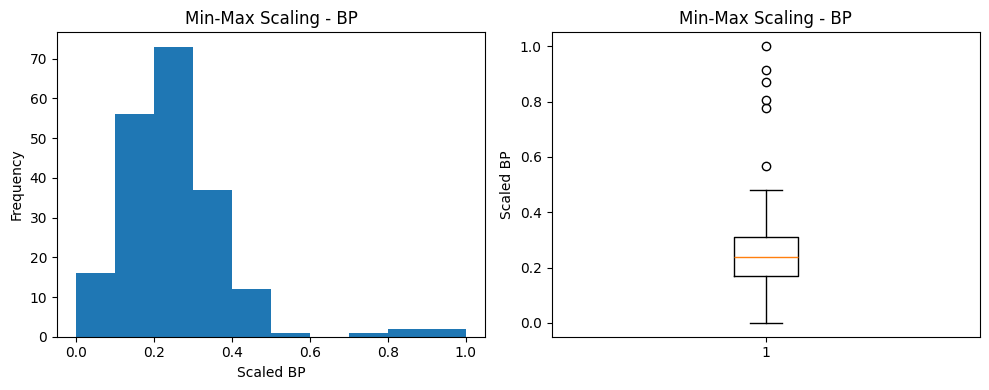

In [30]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(df["bp_scaled"])
plt.title("Min-Max Scaling - BP")
plt.xlabel("Scaled BP")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.boxplot(df["bp_scaled"])
plt.title("Min-Max Scaling - BP")
plt.ylabel("Scaled BP")

plt.tight_layout()
plt.show()

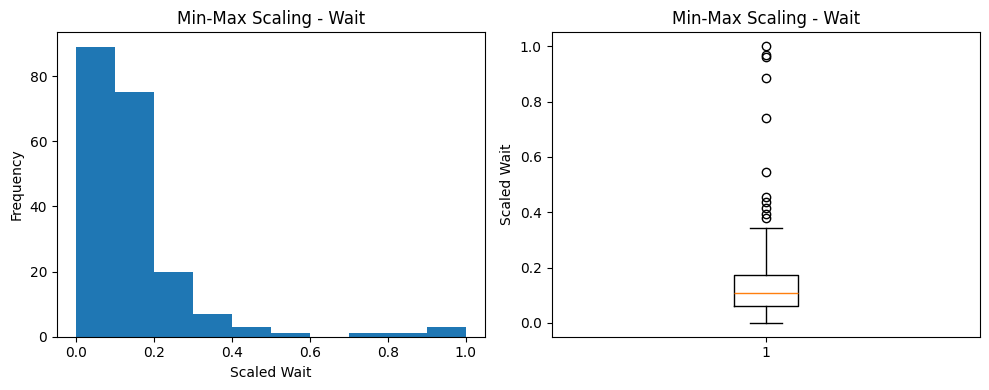

In [31]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(df["wait_scaled"])
plt.title("Min-Max Scaling - Wait")
plt.xlabel("Scaled Wait")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.boxplot(df["wait_scaled"])
plt.title("Min-Max Scaling - Wait")
plt.ylabel("Scaled Wait")

plt.tight_layout()
plt.show()

bp: The x-axis changed from the original BP values to 0–1, while the distribution shape stayed the same.
wait: The x-axis changed from the original waiting-time values to 0–1, while the right-skewed shape and outliers stayed the same.

Useful when a model or calculation requires values to start from 0, such as adjusting data for easier comparison.
Limitation: It does not change the distribution’s shape or remove skewness and outliers.


B.3 Max Scaling ( x / max )

In [32]:
df["bp_max"] = df["bp"] / df["bp"].max()
df["wait_max"] = df["wait"] / df["wait"].max()

In [33]:
print("BP min:", df["bp_max"].min())
print("BP max:", df["bp_max"].max())

BP min: 0.39800995024875624
BP max: 1.0


In [35]:
print("Wait min:", df["wait_max"].min())
print("Wait max:", df["wait_max"].max())

Wait min: 0.005729486392469818
Wait max: 1.0


No, the minimum of bp_max is not the same as the minimum of bp_mm.
bp_max divides values only by the maximum, so the minimum does not become 0.

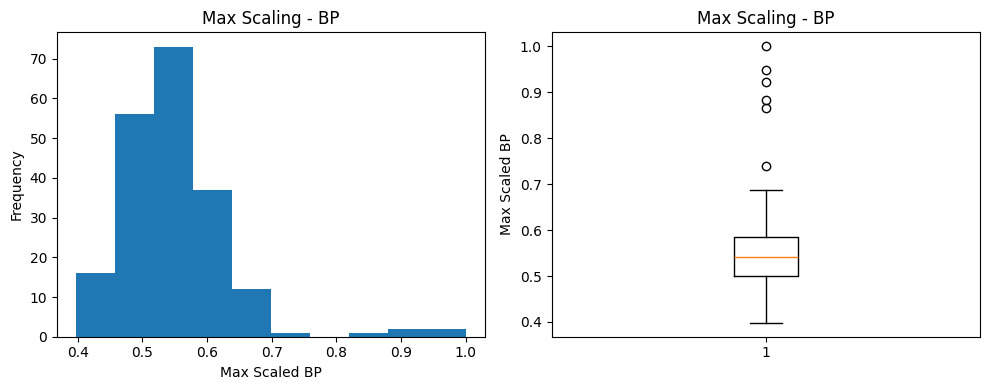

In [36]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(df["bp_max"])
plt.title("Max Scaling - BP")
plt.xlabel("Max Scaled BP")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.boxplot(df["bp_max"])
plt.title("Max Scaling - BP")
plt.ylabel("Max Scaled BP")

plt.tight_layout()
plt.show()

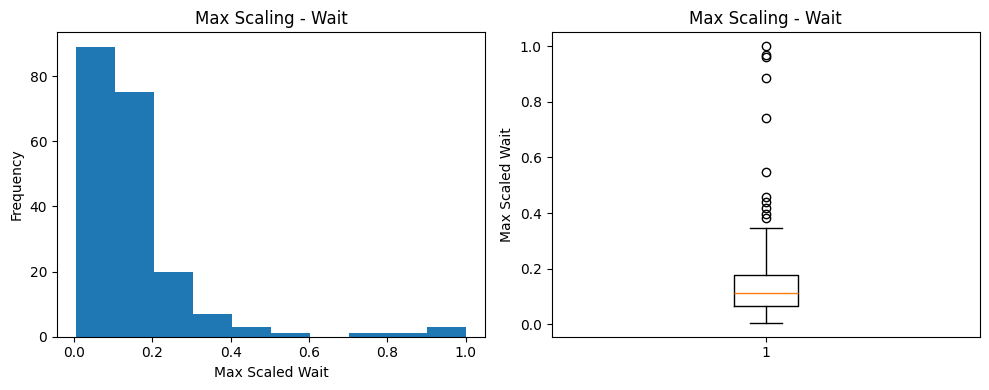

In [37]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(df["wait_max"])
plt.title("Max Scaling - Wait")
plt.xlabel("Max Scaled Wait")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.boxplot(df["wait_max"])
plt.title("Max Scaling - Wait")
plt.ylabel("Max Scaled Wait")

plt.tight_layout()
plt.show()

bp: The values are scaled to a maximum of 1, but the minimum is not 0. The distribution shape and outliers stay the same.
wait: The values are also scaled to a maximum of 1, while the strong right-skew and outliers remain.
The minimum is not 0 because max scaling only divides by the maximum; it does not subtract the minimum.

B.4 Min-Max Scaling ( (x − min) / (max − min) )

In [38]:
df["bp_mm"] = scaler.fit_transform(df[["bp"]])
df["wait_mm"] = scaler.fit_transform(df[["wait"]])

In [39]:
print("BP min:", df["bp_mm"].min())
print("BP max:", df["bp_mm"].max())

BP min: 0.0
BP max: 1.0


In [40]:
print("Wait min:", df["wait_mm"].min())
print("Wait max:", df["wait_mm"].max())

Wait min: 0.0
Wait max: 1.0


both columns have minimum = 0 and maximum = 1.

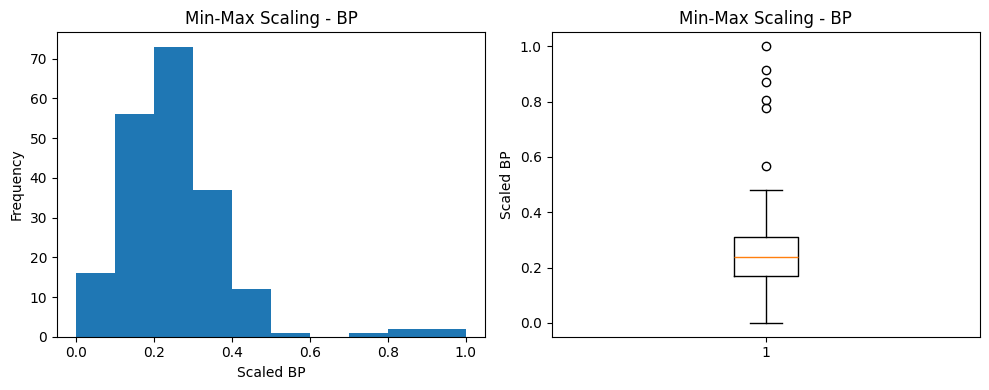

In [41]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(df["bp_mm"])
plt.title("Min-Max Scaling - BP")
plt.xlabel("Scaled BP")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.boxplot(df["bp_mm"])
plt.title("Min-Max Scaling - BP")
plt.ylabel("Scaled BP")

plt.tight_layout()
plt.show()

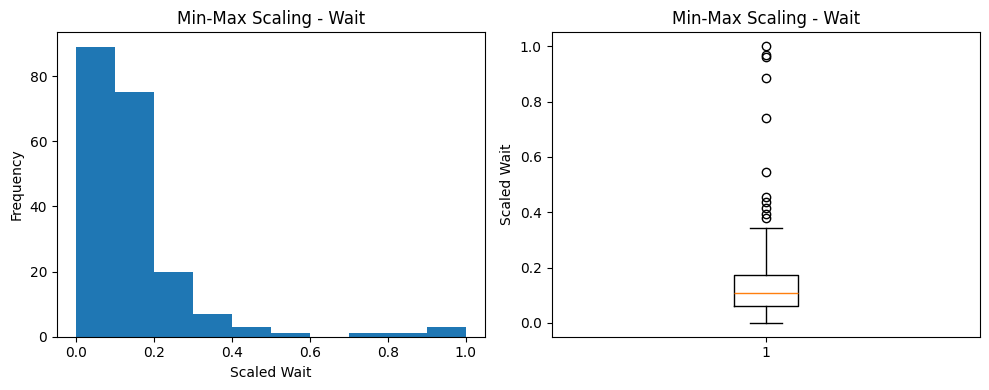

In [42]:

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(df["wait_mm"])
plt.title("Min-Max Scaling - Wait")
plt.xlabel("Scaled Wait")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.boxplot(df["wait_mm"])
plt.title("Min-Max Scaling - Wait")
plt.ylabel("Scaled Wait")

plt.tight_layout()
plt.show()

bp: Outliers are still visible near the high end, but their values are compressed into the 0–1 range.
wait: The high outliers are strongly compressed near 1.

Min-max scaling is sensitive to outliers because the minimum and maximum values determine the scaling range.

B.5 Z-Score Normalisation ( (x − mean) / std )

In [43]:
df["bp_z"] = (df["bp"] - df["bp"].mean()) / df["bp"].std()
df["wait_z"] = (df["wait"] - df["wait"].mean()) / df["wait"].std()

In [44]:
print("BP mean:", df["bp_z"].mean())
print("BP std:", df["bp_z"].std())

BP mean: 3.7747582837255325e-17
BP std: 0.9999999999999999


In [45]:
print("Wait mean:", df["wait_z"].mean())
print("Wait std:", df["wait_z"].std())

Wait mean: 8.881784197001253e-18
Wait std: 1.0


 mean and standard deviation are usually approximately 0 and 1,

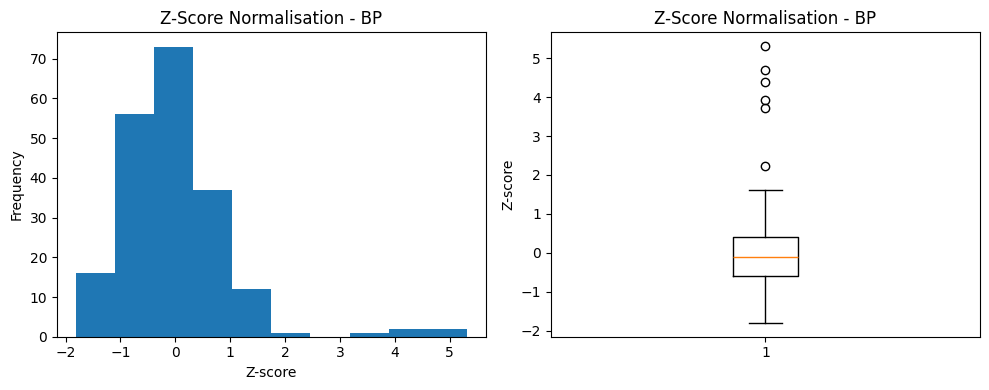

In [46]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(df["bp_z"])
plt.title("Z-Score Normalisation - BP")
plt.xlabel("Z-score")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.boxplot(df["bp_z"])
plt.title("Z-Score Normalisation - BP")
plt.ylabel("Z-score")

plt.tight_layout()
plt.show()

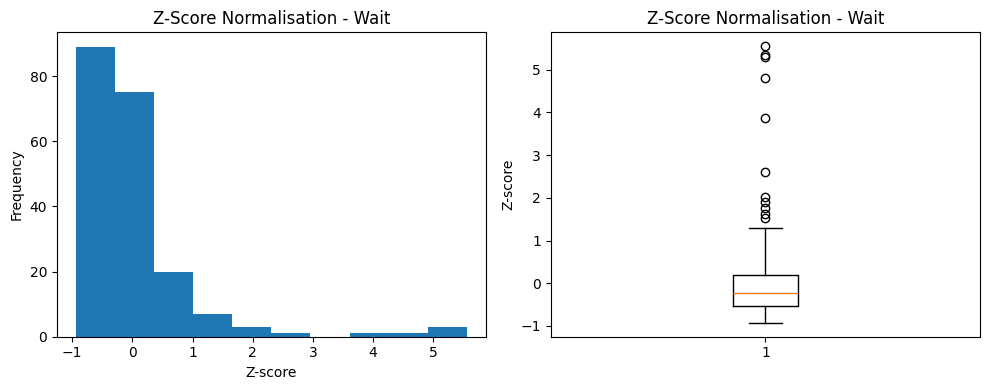

In [47]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(df["wait_z"])
plt.title("Z-Score Normalisation - Wait")
plt.xlabel("Z-score")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.boxplot(df["wait_z"])
plt.title("Z-Score Normalisation - Wait")
plt.ylabel("Z-score")

plt.tight_layout()
plt.show()

bp: The outliers are at high positive z-scores, with some likely beyond +3.
wait: Several outliers are far above +3, showing extreme waiting times.
A z-score of +4 means the value is 4 standard deviations above the mean.
Yes, the extreme outliers can be beyond ±3.

The shape stayed almost the same, but the x-axis changed from the original BP values (around 88–221) to standardized z-scores centered around 0.

B.6 IQR / Robust Scaling ( (x − median) / IQR )

In [48]:
df["bp_iqr"] = (df["bp"] - df["bp"].median()) / (df["bp"].quantile(0.75) - df["bp"].quantile(0.25))

df["wait_iqr"] = (df["wait"] - df["wait"].median()) / (df["wait"].quantile(0.75) - df["wait"].quantile(0.25))

In [49]:
print("BP Median:", df["bp_iqr"].median())
print("BP IQR:", df["bp_iqr"].quantile(0.75) - df["bp_iqr"].quantile(0.25))

BP Median: -3.7339922820400773e-16
BP IQR: 0.9999999999999996


In [50]:
print("Wait Median:", df["wait_iqr"].median())
print("Wait IQR:", df["wait_iqr"].quantile(0.75) - df["wait_iqr"].quantile(0.25))

Wait Median: 0.0
Wait IQR: 1.0


So, median = 0 and IQR = 1 for both columns.

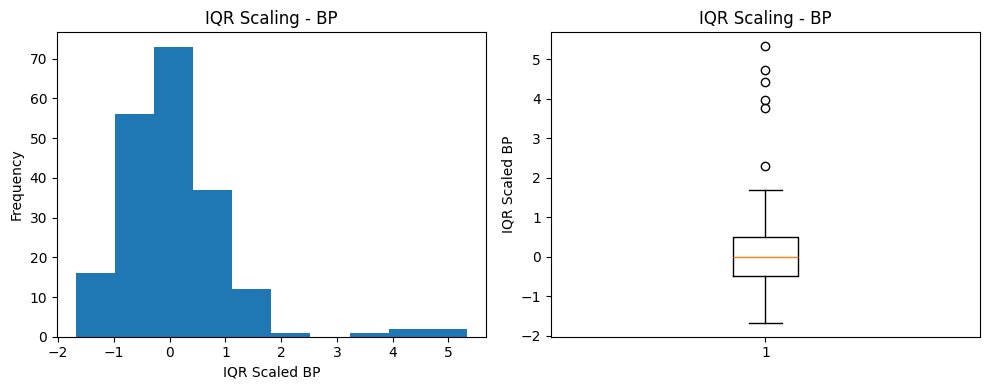

In [51]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(df["bp_iqr"])
plt.title("IQR Scaling - BP")
plt.xlabel("IQR Scaled BP")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.boxplot(df["bp_iqr"])
plt.title("IQR Scaling - BP")
plt.ylabel("IQR Scaled BP")

plt.tight_layout()
plt.show()

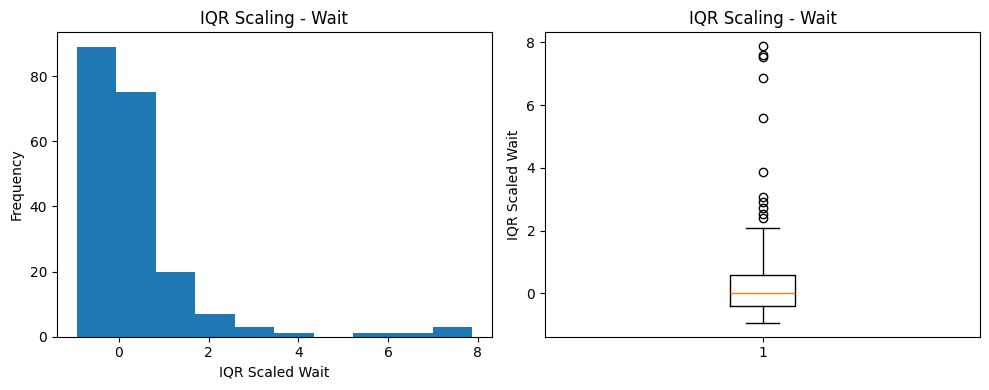

In [52]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(df["wait_iqr"])
plt.title("IQR Scaling - Wait")
plt.xlabel("IQR Scaled Wait")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.boxplot(df["wait_iqr"])
plt.title("IQR Scaling - Wait")
plt.ylabel("IQR Scaled Wait")

plt.tight_layout()
plt.show()

The outliers appear farther from the box compared with z-score scaling.
IQR scaling uses the middle 50% of the data, so extreme values have less influence on the scale.
Therefore, the main data stays more compact while outliers are pushed farther away.

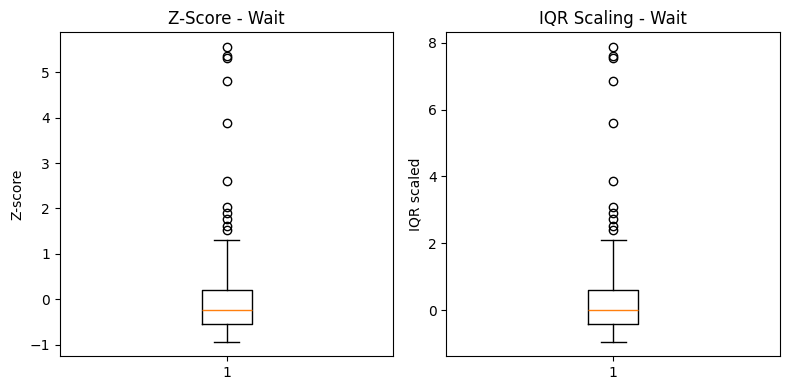

In [53]:
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.boxplot(df["wait_z"])
plt.title("Z-Score - Wait")
plt.ylabel("Z-score")

plt.subplot(1, 2, 2)
plt.boxplot(df["wait_iqr"])
plt.title("IQR Scaling - Wait")
plt.ylabel("IQR scaled")

plt.tight_layout()
plt.show()

I would prefer IQR scaling for data with many extreme outliers because it is less affected by outliers and keeps the main data more compact.

B.7 Summary Comparison

In [54]:
bp_all = df[["bp", "bp_scaled", "bp_max", "bp_mm", "bp_z", "bp_iqr"]]

print(bp_all.describe())

               bp   bp_scaled      bp_max       bp_mm          bp_z  \
count  200.000000  200.000000  200.000000  200.000000  2.000000e+02   
mean   121.723000    0.253366    0.550534    0.253366  3.774758e-17   
std     18.717089    0.140624    0.084654    0.140624  1.000000e+00   
min     88.000000    0.000000    0.398010    0.000000 -1.801722e+00   
25%    110.400000    0.168295    0.499322    0.168295 -6.049552e-01   
50%    119.800000    0.238918    0.541836    0.238918 -1.027403e-01   
75%    129.425000    0.311232    0.585369    0.311232  4.114956e-01   
max    221.100000    1.000000    1.000000    1.000000  5.309426e+00   

             bp_iqr  
count  2.000000e+02  
mean   1.010775e-01  
std    9.838154e-01  
min   -1.671485e+00  
25%   -4.940867e-01  
50%   -3.729655e-16  
75%    5.059133e-01  
max    5.324573e+00  


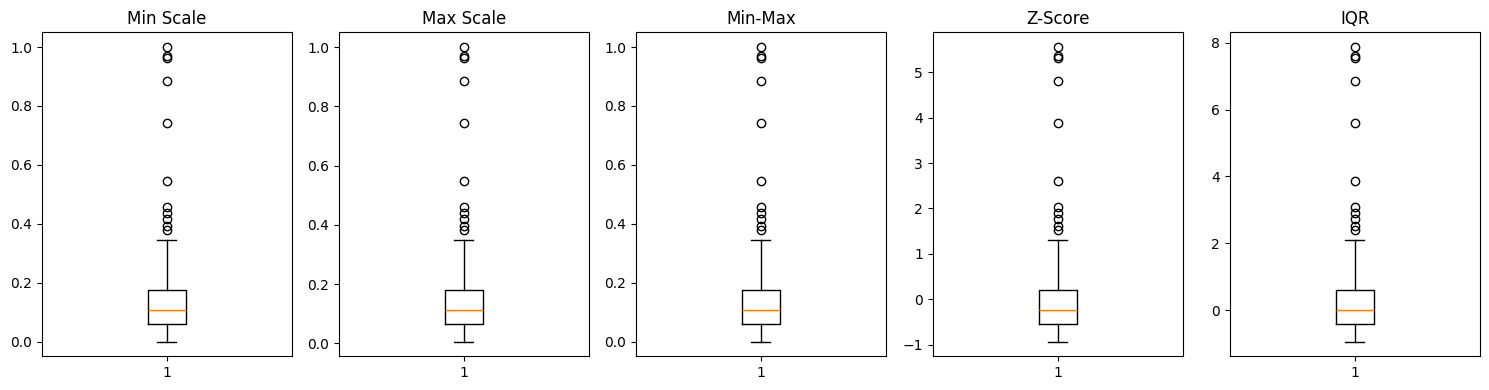

In [55]:
fig, ax = plt.subplots(1, 5, figsize=(15, 4))

data = [
    df["wait_scaled"],
    df["wait_max"],
    df["wait_mm"],
    df["wait_z"],
    df["wait_iqr"]
]

names = ["Min Scale", "Max Scale", "Min-Max", "Z-Score", "IQR"]

for i in range(5):
    ax[i].boxplot(data[i])
    ax[i].set_title(names[i])

plt.tight_layout()
plt.show()

Min-max scaling and max scaling compress the main body of the data into a small range, while z-score and IQR scaling spread the values more.

IQR scaling makes the outliers look the most extreme, with some reaching nearly 8 on the scale.

For K-NN with outliers, I would choose IQR scaling because it is less affected by extreme values. Z-score and Min-Max scaling are more sensitive to outliers. IQR scaling keeps the main data compact while handling outliers better.

Take-Home

In [56]:
bimodal = np.concatenate([
    rng.normal(50, 5, 100),
    rng.normal(150, 5, 100)
])

df["bimodal"] = bimodal

df["bimodal_min"] = df["bimodal"] - df["bimodal"].min()
df["bimodal_max"] = df["bimodal"] / df["bimodal"].max()
df["bimodal_mm"] = (df["bimodal"] - df["bimodal"].min()) / (df["bimodal"].max() - df["bimodal"].min())
df["bimodal_z"] = (df["bimodal"] - df["bimodal"].mean()) / df["bimodal"].std()
df["bimodal_iqr"] = (df["bimodal"] - df["bimodal"].median()) / (df["bimodal"].quantile(0.75) - df["bimodal"].quantile(0.25))

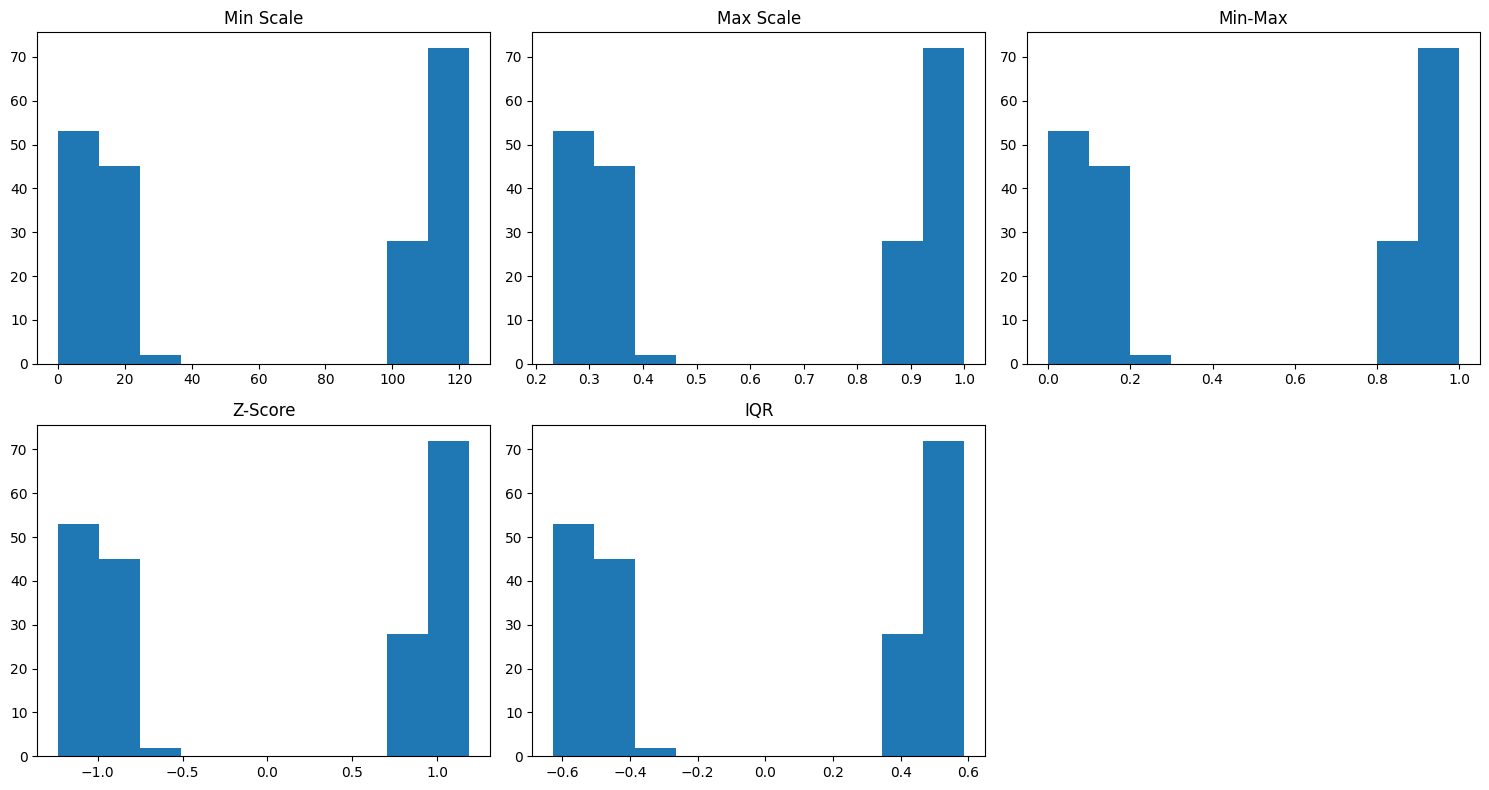

In [57]:
plt.figure(figsize=(15, 8))

columns = ["bimodal_min", "bimodal_max", "bimodal_mm", "bimodal_z", "bimodal_iqr"]
titles = ["Min Scale", "Max Scale", "Min-Max", "Z-Score", "IQR"]

for i in range(5):
    plt.subplot(2, 3, i + 1)
    plt.hist(df[columns[i]])
    plt.title(titles[i])

plt.tight_layout()
plt.show()

In [59]:
def min_max_scale(arr):
    mini = min(arr)
    maxi = max(arr)
    
    return [(x - mini) / (maxi - mini) for x in arr]


def z_score_scale(arr):
    mean = sum(arr) / len(arr)
    std = (sum((x - mean) ** 2 for x in arr) / (len(arr) - 1)) ** 0.5
    
    return [(x - mean) / std for x in arr]

In [60]:
bp = df["bp"].tolist()

bp_mm_manual = min_max_scale(bp)
bp_z_manual = z_score_scale(bp)

print(np.allclose(bp_mm_manual, df["bp_mm"]))
print(np.allclose(bp_z_manual, df["bp_z"]))

True
True


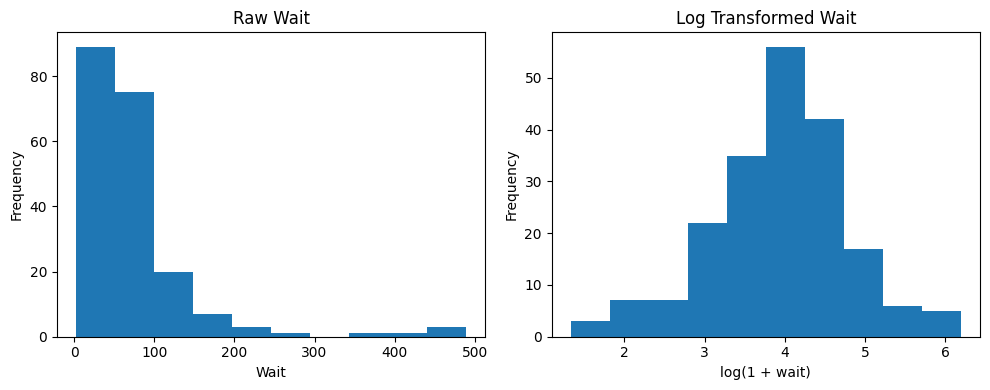

In [62]:


df["wait_log"] = np.log1p(df["wait"])

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(df["wait"])
plt.title("Raw Wait")
plt.xlabel("Wait")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.hist(df["wait_log"])
plt.title("Log Transformed Wait")
plt.xlabel("log(1 + wait)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()